# 12-4. X3_l1 (X3) AR단독 모델 비교 ((d, D) 4가지)

AR단독 모델에서 (d, D) = (0,0), (0,1), (1,0), (1,1)를 CRPS, MSE, 커버리지로 비교한다.

- **조합**: (d, D) 4 x 스케일(원, 로그) 2 x 구간(자체, 리샘플링) 2 = 16개
- **구현**: `12-3`의 일반화 구현. 절편은 `d + D == 0`일 때만, (p, P)는 AR단독 auto_arima(`seasonal=True, m=4, max_Q=0`, AICc)가 선택
- **평가**: 채점 origin 22개(origin 35 (~2019Q3) ~ 56 (~2024Q4)), CRPS는 `crps_ensemble`, 리샘플링은 `o' + h <= o`인 오차만 사용(11시리즈와 같은 방식)
- **단위 상수**: 모델에 넣는 값은 origin마다 그 시점까지의 훈련 구간 표준편차로 `100 / 표준편차`를 곱해 맞춘다(미래 정보 없음)
- **선정 규칙**: CRPS 1등의 ±10% 이내 중 커버리지가 90%에 가장 가까운 것

## 1. 구현 (AR단독)

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')
from dataclasses import dataclass
import numpy as np
import pandas as pd
import pmdarima as pm
import properscoring as ps
from scipy import stats

H, ALPHA, P_MAX = 4, 0.10, 3
Z = stats.norm.ppf(1 - ALPHA / 2)


@dataclass(frozen=True)
class Spec:
    d: int = 1
    D: int = 0
    m: int = 4
    seasonal_ar: bool = False        # True면 계절 AR 차수 P도 AR단독 auto_arima가 탐색(D > 0이면 항상 탐색)

    @property
    def const(self):
        return self.d + self.D == 0


# ---------------------------------------------------------------- 구조 선택 (AR단독 auto_arima)
def select_structure(train, sp):
    kw = dict(d=sp.d, start_q=0, max_q=0, max_p=P_MAX, information_criterion="aicc", with_intercept=sp.const,
              suppress_warnings=True, error_action="ignore")
    if sp.D or sp.seasonal_ar:
        m = pm.auto_arima(train, seasonal=True, m=sp.m, D=sp.D, start_Q=0, max_Q=0, **kw)
        return m.order[0], m.seasonal_order[0], m
    m = pm.auto_arima(train, seasonal=False, **kw)
    return m.order[0], 0, m


def ar_forecast(m):
    fc, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    return np.asarray(fc), (conf[:, 1] - conf[:, 0]) / (2 * Z)


def ar_only(train, sp):
    p, P, m = select_structure(train, sp)
    fc, sig = ar_forecast(m)
    return fc, sig, (p, P)


## 2. 계산

모든 origin(20~56)에서 적합해 오차 표본을 쌓고 채점 origin(35~56)만 평가한다. 로그는 `100 x log(y)`에서 적합해 원 스케일로 되돌려 채점한다.

In [2]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
vals = raw[["quarter", "X3_l1"]].dropna()["X3_l1"].values.astype(float)
SCALE, N_ENS, INITIAL_CALIB = 100.0, 500, 15
SEED = 42                                               # 리샘플링 난수 시드(모든 변수, 모델, (d, D)가 같은 시드를 써서 같은 난수로 비교한다)
var_std = vals.std()
origins = list(range(20, len(vals) - H + 1))
U = stats.norm.ppf((np.arange(N_ENS) + 0.5) / N_ENS)
CASES = [(0, 0), (0, 1), (1, 0), (1, 1)]
CACHE = "../cache/cache_134_ar_dD_df.pkl"


def run(sp, logmode):
    rng = np.random.default_rng(SEED)
    tf = (lambda x: np.exp(np.asarray(x) / SCALE)) if logmode else (lambda x: x)
    errs = {h: [] for h in range(1, H + 1)}
    rows = []
    for oi, o in enumerate(origins):
        C = 100 / vals[:o].std()                                     # 단위 상수: 그 시점까지의 훈련 구간 표준편차로 정함(미래 정보 없음)
        series = SCALE * np.log(vals * C) if logmode else vals * C
        train, actual = series[:o], series[o:o + H]
        fc, sig, (p, P) = ar_only(train, sp)
        if oi >= INITIAL_CALIB:
            for h in range(1, H + 1):
                a, s_h = vals[o + h - 1], max(sig[h - 1], 1e-6)
                pool = np.array([e for o2, e in errs[h] if o2 + h <= o]) * (1 if logmode else C)      # 원 스케일 오차는 원래 단위로 저장해 두었다
                samples = fc[h - 1] + rng.choice(pool - np.median(pool), size=N_ENS, replace=True)
                lo_r, hi_r = tf(np.quantile(samples, [ALPHA / 2, 1 - ALPHA / 2])) / C
                lo_n, hi_n = tf(fc[h - 1] - Z * s_h) / C, tf(fc[h - 1] + Z * s_h) / C
                med = float(tf(fc[h - 1])) / C
                base = {"d": sp.d, "D": sp.D, "스케일": "로그" if logmode else "원", "origin": o, "h": h, "p": p, "P": P,
                        "MSE": ((a - med) / var_std) ** 2, "pool_n": len(pool)}
                rows.append({**base, "구간": "리샘플링", "적중": float(lo_r <= a <= hi_r) * 100, "폭": (hi_r - lo_r) / var_std,
                             "crps": ps.crps_ensemble(a, tf(samples) / C) / var_std})
                rows.append({**base, "구간": "자체", "적중": float(lo_n <= a <= hi_n) * 100, "폭": (hi_n - lo_n) / var_std,
                             "crps": ps.crps_ensemble(a, tf(fc[h - 1] + s_h * U) / C) / var_std})
        for h in range(1, H + 1):
            errs[h].append((o, (actual[h - 1] - fc[h - 1]) / (1 if logmode else C)))
    return pd.DataFrame(rows)


if os.path.exists(CACHE):
    res = pd.read_pickle(CACHE)
    print("캐시에서 로드:", len(res), "행")
else:
    res = pd.concat([run(Spec(d=d, D=D), lg) for d, D in CASES for lg in (False, True)], ignore_index=True)
    res.to_pickle(CACHE)
    print("계산 완료:", len(res), "행")

캐시에서 로드: 1408 행


## 3. 11-1 저장 결과와의 차이: (d, D) = (1, 0)

11시리즈는 `X3_l1`에 단위 상수를 곱하지 않았고 리샘플링 시드도 달랐다. 훈련 구간 단위 상수와 시드 42로 바뀐 영향을 본다.

In [3]:
c11 = pd.read_pickle("../cache/cache_107_rank_compare_df.pkl")
c11 = c11[c11["모델"] == "AR단독"].groupby(["스케일", "구간"])[["crps_ensemble", "MSE", "적중"]].mean()
mine = res[(res["d"] == 1) & (res["D"] == 0)].groupby(["스케일", "구간"])[["crps", "MSE", "적중"]].mean()
chk = pd.concat([mine.add_suffix("_new"), c11.rename(columns={"crps_ensemble": "crps"}).add_suffix("_old")], axis=1)
display(chk.round(6))
print("최대 차이:", float(np.abs(mine.values - c11[["crps_ensemble", "MSE", "적중"]].values).max()))

crps_new   MSE_new     적중_new  crps_old   MSE_old     적중_old
스케일 구간                                                                
로그  리샘플링  0.721876  1.345181  70.454545  0.725006  1.345429  70.454545
    자체    0.678776  1.345181  76.136364  0.678832  1.345429  76.136364
원   리샘플링  0.597065  1.127276  62.500000  0.598630  1.127355  63.636364
    자체    0.593045  1.127276  65.909091  0.593065  1.127355  65.909091

최대 차이: 1.1363636363636331


## 4. 16개 조합의 CRPS, MSE, 커버리지

h 평균 -> origin 평균. 커버리지 목표는 90%다.

In [4]:
per = res.groupby(["d", "D", "스케일", "구간", "origin"])[["crps", "MSE", "적중", "폭"]].mean()
tab = per.groupby(["d", "D", "스케일", "구간"]).mean().rename(columns={"crps": "CRPS", "적중": "커버리지(%)"})
display(tab.round(4))

CRPS     MSE  커버리지(%)       폭
d D 스케일 구간                                   
0 0 로그  리샘플링  0.6117  1.2150  75.0000  3.4077
        자체    0.6081  1.2150  77.2727  2.8856
    원   리샘플링  0.6137  1.2308  68.1818  1.9550
        자체    0.6358  1.2308  55.6818  1.4948
  1 로그  리샘플링  1.0182  2.8440  70.4545  6.8455
        자체    0.9483  2.8440  71.5909  5.0071
    원   리샘플링  0.6804  1.5256  70.4545  2.3662
        자체    0.7061  1.5256  60.2273  1.8357
1 0 로그  리샘플링  0.7219  1.3452  70.4545  5.2947
        자체    0.6788  1.3452  76.1364  4.0306
    원   리샘플링  0.5971  1.1273  62.5000  2.0644
        자체    0.5930  1.1273  65.9091  1.7273
  1 로그  리샘플링  1.1654  3.8408  73.8636  8.6684
        자체    1.0991  3.8408  70.4545  6.0890
    원   리샘플링  0.8293  2.2829  71.5909  2.8652
        자체    0.8714  2.2829  54.5455  2.0257

## 5. 모델 선정 규칙 적용

CRPS 1등의 ±10% 이내 중 커버리지가 90%에 가장 가까운 것을 고른다.

In [5]:
best = tab["CRPS"].min()
cand = tab[tab["CRPS"] <= best * 1.10].sort_values("CRPS").pipe(lambda x: x.iloc[np.argsort((x["커버리지(%)"] - 90).abs().values, kind="stable")])
print(f"CRPS 1등 {best:.4f}, 기준 {best * 1.10:.4f} 이내 {len(cand)}개 / 16")
display(cand.round(4))
print("선정:", cand.index[0], "(d, D, 스케일, 구간)")

CRPS 1등 0.5930, 기준 0.6523 이내 6개 / 16


CRPS     MSE  커버리지(%)       폭
d D 스케일 구간                                   
0 0 로그  자체    0.6081  1.2150  77.2727  2.8856
        리샘플링  0.6117  1.2150  75.0000  3.4077
    원   리샘플링  0.6137  1.2308  68.1818  1.9550
1 0 원   자체    0.5930  1.1273  65.9091  1.7273
        리샘플링  0.5971  1.1273  62.5000  2.0644
0 0 원   자체    0.6358  1.2308  55.6818  1.4948

선정: (np.int64(0), np.int64(0), '로그', '자체') (d, D, 스케일, 구간)


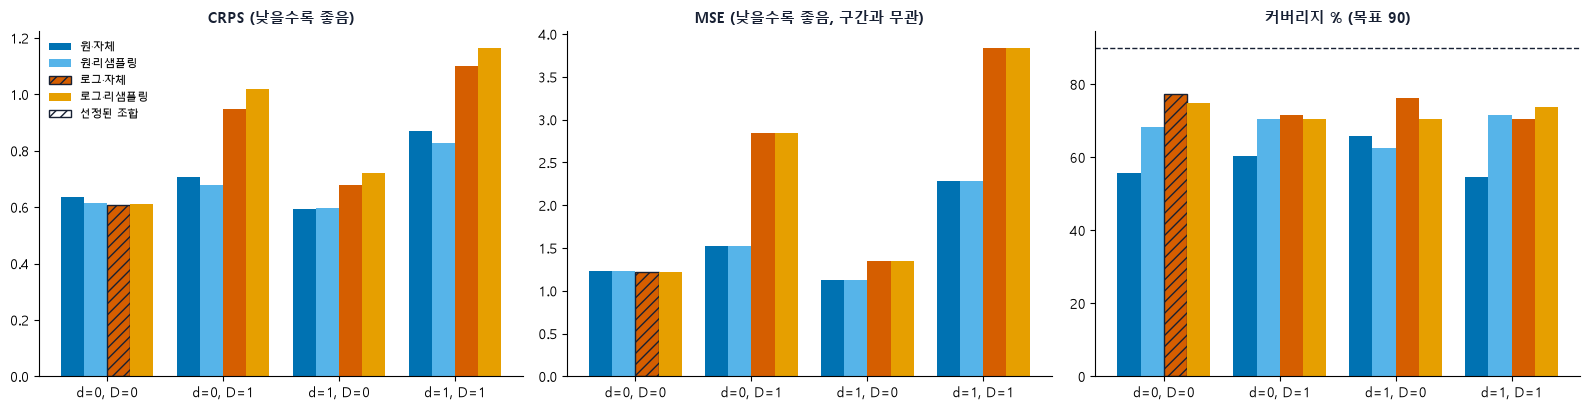

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
cols = {("원", "자체"): "#0072B2", ("원", "리샘플링"): "#56B4E9", ("로그", "자체"): "#D55E00", ("로그", "리샘플링"): "#E69F00"}
x = np.arange(len(CASES))
for ax, c, ttl in zip(axes, ["CRPS", "MSE", "커버리지(%)"], ["CRPS (낮을수록 좋음)", "MSE (낮을수록 좋음, 구간과 무관)", "커버리지 % (목표 90)"]):
    for j, ((sc, iv), col) in enumerate(cols.items()):
        v = [tab.loc[(d, D, sc, iv), c] for d, D in CASES]
        bars = ax.bar(x + (j - 1.5) * 0.2, v, 0.2, color=col, label=f"{sc}·{iv}")
        for (d, D), b in zip(CASES, bars):
            if (d, D, sc, iv) == tuple(cand.index[0]):                  # 5절에서 선정된 조합
                b.set_hatch("///")
                b.set_edgecolor("#172033")
    ax.set_xticks(x)
    ax.set_xticklabels([f"d={d}, D={D}" for d, D in CASES])
    ax.set_title(ttl, fontsize=10.5, fontweight="bold", color="#172033")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[2].axhline(90, color="#172033", linestyle="--", linewidth=1)
from matplotlib.patches import Patch
h_, l_ = axes[0].get_legend_handles_labels()
axes[0].legend(h_ + [Patch(facecolor="white", edgecolor="#172033", hatch="///")], l_ + ["선정된 조합"], fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

## 6. 선택된 구조 (p, P)

(d, D)별 AR단독이 고른 (p, P) 분포다.

In [7]:
st = res[(res["스케일"] == "원") & (res["구간"] == "자체") & (res["h"] == 1)]
display(st.groupby(["d", "D"]).apply(lambda g: pd.Series({"(p,P) 분포": dict(g.groupby(["p", "P"]).size())})))

(p,P) 분포
d D                                               
0 0                        {(2, 0): 14, (3, 0): 8}
  1             {(2, 1): 6, (2, 2): 14, (3, 2): 2}
1 0                        {(1, 0): 18, (2, 0): 4}
  1  {(1, 1): 3, (1, 2): 14, (2, 1): 1, (2, 2): 4}

## 결론

- **11-1과의 차이**: (d, D) = (1, 0)의 4개 조합이 11-1 저장 결과와 거의 같다(CRPS 최대 차이 0.003, 적중은 88개 중 1개 예측 차이). 단위 상수를 훈련 구간 표준편차로 바꾸고 리샘플링 시드를 42로 통일한 영향이다.
- **D=1은 도움이 안 된다**: CRPS와 MSE가 모두 나빠졌다(원·자체 CRPS 0.59 -> 0.87, d=1 기준). 4분기 합이라 계절성이 이미 상쇄되어 있다.
- **d=0 대 d=1**: CRPS 1등은 (1, 0)·원·자체(0.5930)이고 (0, 0)·원·리샘플링(0.6137)이 3.5% 차이로 뒤따른다. MSE는 (1, 0)이 더 낮다(1.13 대 1.23).
- **커버리지는 모든 조합이 90%에 못 미친다**(55~77%).
- **선정**: (0, 0)·로그·자체(CRPS 0.6081, 커버리지 77.3%)가 뽑혔지만, 커버리지 우위는 구간 폭이 넓어서(2.89 대 1.73) 생긴 면이 커 (d, D)의 우열 근거로는 약하다.


## 최종 정리

CRPS 1등과 선정 조합(CRPS 1등의 ±10% 이내 중 커버리지가 90%에 가장 가까운 것)이다.

In [8]:
def _lab(i):
    i = tuple(i)
    m = i[0] + "·" if isinstance(i[0], str) and i[0] in ("AR단독", "GARCH", "SV") else ""
    d, D, sc, iv = i[-4:]
    return f"{m}({int(d)},{int(D)})·{sc}·{iv}"


_fin = tab[np.isfinite(tab["CRPS"])]
_top, _sel = _fin["CRPS"].idxmin(), cand.index[0]
final = pd.DataFrame([_fin.loc[_top], _fin.loc[_sel]], index=["CRPS 1등", "선정"])[["CRPS", "MSE", "커버리지(%)", "폭"]]
final.insert(0, "조합", [_lab(_top), _lab(_sel)])
with pd.option_context("display.float_format", "{:,.4f}".format, "display.width", 200):
    display(final)
print(f"CRPS 1등: {_lab(_top)} / 선정: {_lab(_sel)}" + (" (같은 조합)" if _top == _sel else ""))

,조합,CRPS,MSE,커버리지(%),폭
CRPS 1등,"(1,0)·원·자체",0.5930,1.1273,65.9091,1.7273
선정,"(0,0)·로그·자체",0.6081,1.2150,77.2727,2.8856


CRPS 1등: (1,0)·원·자체 / 선정: (0,0)·로그·자체
